<a href="https://colab.research.google.com/github/Paudelcas/MPM_200_Delcastillo/blob/main/assignment_1_will__hummers_survive.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/EpiPandit/MPM_200/blob/main/Session%205/Assignment%201%20-%20Will%20the%20Hummers%20Survive.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🐦 MPM 200 · Week 1 Assignment: *Will the Hummers Survive?*

**Due:** Wednesday 28 October 2026, 9:00 AM · **Total:** 50 points + 5 bonus

**Ground rules**
* Show your work: code **and** output. It lets us follow your thinking and give partial credit.
* Work together, but don't copy. Read each other's code until you could have written it yourself.
* Cells with blanks (`____`) won't run until you fill them in. That's on purpose.

## 📟 Mission briefing

You're the wildlife veterinarian on call for three California wildlife rehabilitation centers. Every year, hummingbirds arrive in shoeboxes and teacups: stunned by windows, carried in by cats, fallen from nests. Some go on to fly again; many don't.

The centers have pooled **more than 25 years of intake records (1991–2016)**. Your mission is to find out **which birds make it back to the sky, and what tips the odds.**

### 🗂️ Case file: data dictionary

| Column | What it records |
|---|---|
| `Admitted` | Date the bird arrived at the center |
| `Disposition_binary` | Outcome: **Died** or **Released** |
| `Place` | Rehabilitation center |
| `F_Aid` | Did the finder give first aid? (Yes/No) |
| `Species_e` | `ANHU` = Anna's Hummingbird · `BCHU` = Black-chinned Hummingbird · `Selasphorus` = orange *Selasphorus* species (e.g., Allen's, Rufous) not identified to species · `Non-selasphorus` = green birds not identified to species |
| `Sex_e`, `Age_e` | Sex and age class as recorded |
| `Brought_in_after` | Days the finder kept the bird before bringing it in |
| `season` | Season of admission |
| `r` | Reason for admission |
| `Green_Orange` | Broad group: green (non-*Selasphorus*) or orange (*Selasphorus*) |
| `ID` | Unique ID for each bird |

## 🍄 Case file 0 · Warm-up: make some noise (2 pts)

**Q0.** Install **beepr** and play the **Mario** sound. Then have a cowsay animal welcome you to the mission (use your name!).

> **Why the helper below?** `beep()` plays sound on the computer *running R*. On Colab that's a Google server with no speakers, so you'd hear nothing. The helper sends the very same sound file to **your browser** instead. On your own laptop, plain `beep("mario")` works.

In [3]:
install.packages(c("beepr", "cowsay"))
library(beepr)
library(cowsay)

# Plays a beepr sound in your browser (for Colab)
beep_colab <- function(sound = "smb_stage_clear") {     # smb_stage_clear = the Mario sound
  wav <- list.files(system.file("sounds", package = "beepr"),
                    pattern = sound, full.names = TRUE)[1]
  b64 <- jsonlite::base64_enc(readBin(wav, "raw", file.info(wav)$size))
  IRdisplay::display_html(sprintf('<audio controls autoplay src="data:audio/wav;base64,%s"></audio>', b64))
}

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [4]:
beep_colab()     # press ▶ if your browser blocks autoplay
say("Welcome to Hummingbird HQ, Dr. Paulina!", by = "cat")


 _________________________________________ 
< Welcome to Hummingbird HQ, Dr. Paulina! >
 ----------------------------------------- 
         \
          \

            |\___/|
          ==) ^Y^ (==
            \  ^  /
             )=*=(
            /     \
            |     |
           /| | | |\
           \| | |_|/\
      jgs  //_// ___/
               \_)

In [5]:
library(dplyr)
library(ggplot2)
options(repr.plot.width = 7, repr.plot.height = 4.5)
dir.create("outputs", showWarnings = FALSE)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




## 📋 Case file 1 · Intake: read the records

**Q1 (2 pts).** Read `Hummingbird_data.csv` into an object called `data`. It lives on the course GitHub, so you can read it straight from the URL.

In [6]:
getwd()


[1] "/content"

In [7]:
data <- read.csv("/content/data_raw/Hummingbird_data.csv")
colnames(data)

[1] "Admitted"           "Disposition_binary" "Place"             
 [4] "F_Aid"              "Species_e"          "Sex_e"             
 [7] "Age_e"              "Brought_in_after"   "season"            
[10] "r"                  "Green_Orange"       "ID"

**Q2 (1 pt).** 🔮 *Predict first:* 26 years, three centers. Guess how many birds: `____`.
Now find how many rows and columns `data` has.

In [8]:
# your code here
dim(data)
nrow(data)
ncol(data)

[1] 6908   12

[1] 6908

[1] 12

**Q3 (3 pts).** Check the structure of the data.
* Use `str()` to see each column.
* Use `sapply()` with `class` to list every column's data type.
* Which columns are text (`character`) and which are numbers? Is `Admitted` stored as a date? Note anything that looks odd.

In [9]:
str(data)

data_types <- sapply(data, class)
print(data_types)

'data.frame':	6908 obs. of  12 variables:
 $ Admitted          : chr  "1/2/1991" "1/2/1991" "1/4/1991" "1/5/1991" ...
 $ Disposition_binary: chr  "Died" "Released" "Died" "Died" ...
 $ Place             : chr  "Lindsey" "Lindsey" "Lindsey" "Lindsey" ...
 $ F_Aid             : chr  "No" "Yes" "No" "No" ...
 $ Species_e         : chr  "ANHU" "ANHU" "ANHU" "ANHU" ...
 $ Sex_e             : chr  "Female-like " "Female-like " "Female-like " "Female-like " ...
 $ Age_e             : chr  "adult-like" "adult-like" "adult-like" "adult-like" ...
 $ Brought_in_after  : int  1 0 0 4 0 0 0 0 0 0 ...
 $ season            : chr  "Winter" "Winter" "Winter" "Winter" ...
 $ r                 : chr  "found on the ground" "unknown" "suspect torpor-like state" "unknown" ...
 $ Green_Orange      : chr  "Non-selasphorus spp." "Non-selasphorus spp." "Non-selasphorus spp." "Non-selasphorus spp." ...
 $ ID                : chr  "1_ANHU" "2_ANHU" "3_ANHU" "4_ANHU" ...
          Admitted Disposition_binary      

✍️ **Your answer:**

### 🎲 Draw your own reproducible sample
Each of you will analyse a random sample of 5,000 birds. `set.seed()` makes "random" **repeatable**: the same seed always gives the same sample, so your instructor can reproduce your results exactly (remember the reproducibility checklist from lecture?).

👉 Replace `1225` with **your birthday as MMDD** (e.g., 3 July → `0703`, which R reads as 703).

In [10]:
set.seed(1022)                              # ← your birthday, MMDD
model_data <- slice_sample(data, n = 5000)

**Use `model_data` for the rest of the assignment.**

**Q4 (1 pt).** How many rows and columns does `model_data` have?

In [11]:
# your code here
nrow(model_data)
ncol(model_data)
str(model_data)

[1] 5000

[1] 12

'data.frame':	5000 obs. of  12 variables:
 $ Admitted          : chr  "11/12/1995" "5/17/2016" "2/25/2004" "4/1/1998" ...
 $ Disposition_binary: chr  "Died" "Died" "Released" "Released" ...
 $ Place             : chr  "Lindsey" "malibu" "Lindsey" "Lindsey" ...
 $ F_Aid             : chr  "Yes" "Yes" "No" "No" ...
 $ Species_e         : chr  "ANHU" "Selasphorus" "ANHU" "ANHU" ...
 $ Sex_e             : chr  "Female-like " "unknown" "Female-like " "Female-like " ...
 $ Age_e             : chr  "adult-like" "Nestling" "adult-like" "adult-like" ...
 $ Brought_in_after  : int  0 0 1 0 2 0 1 0 0 0 ...
 $ season            : chr  "Fall" "Spring" "Winter" "Spring" ...
 $ r                 : chr  "found on the ground" "nest-related" "found on the ground" "window hit" ...
 $ Green_Orange      : chr  "Non-selasphorus spp." "Selasphorus spp." "Non-selasphorus spp." "Non-selasphorus spp." ...
 $ ID                : chr  "932_ANHU" "6732_ALHU" "2618_ANHU" "1365_ANHU" ...


**Q5 (2 pts).** How many columns are **categorical** and how many are **continuous**? Name the continuous one(s). Is `ID` a useful variable for analysis?

✍️ **Your answer:**

10 columns/variables are categorical, 9 if you dont count ID number because it is not useful for analysis. Addmitted is a date which is a continous variable and brought_in_after is a discrete variable.

**Q6 (2 pts).** Save your sample as `Hummingbird_data_YOURNAME.csv` in the `outputs` folder, and submit it. Use `row.names = FALSE`.

In [12]:
write.csv(model_data, "outputs/Hummingbird_data_delcastillo.csv", row.names = FALSE)

## 🏥 Case file 2 · Which hospital is busiest?

Let's count how many birds each center admitted (column `Place`), using dplyr to build a summary table and ggplot2 to plot it.

In [13]:
rehab <- model_data %>%
  group_by(Place) %>%
  summarise(count = n_distinct(ID))
rehab

Place,count
<chr>,<int>
Lindsey,4143
Santa Barbara,65
malibu,792


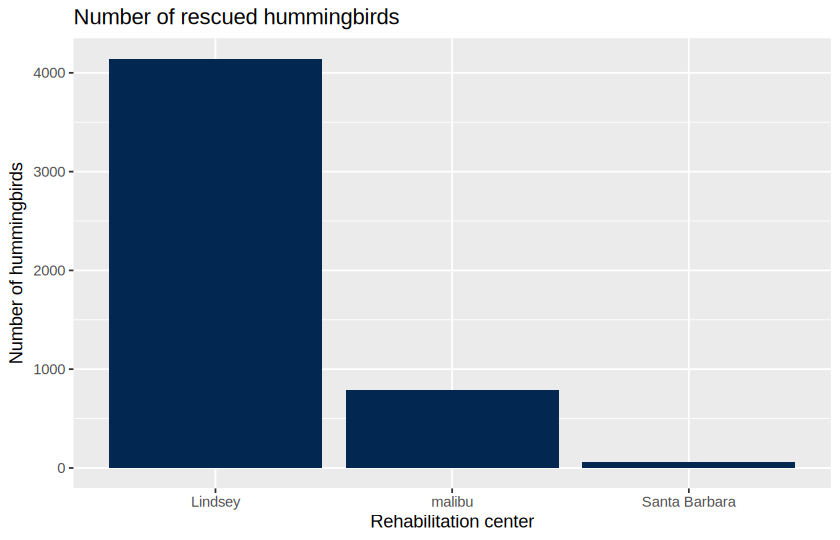

In [14]:
p <- ggplot(rehab, aes(x = Place, y = count)) +
  geom_col(fill = "#022851") +
  xlab("Rehabilitation center") +
  ylab("Number of hummingbirds") +
  labs(title = "Number of rescued hummingbirds")
p

**Q7 (2 pts).** Save this plot as a **PDF, 4 inches wide and 3 inches tall**, and submit it.

In [15]:
ggsave("outputs/rehab_counts_YOURNAME.pdf", p, width = 4, height = 3)

**Q8 (3 pts).** Explain the code in words, line by line, from the line that creates `rehab` through the plot. What does each function do?

✍️ **Your answer:**

The first line is creating a new object called rehab from the model_data dat, then it groups it by place, then for each place it counts every distinct ID numbers.
Then you print rehab.
Then creat a new object called P using ggplot to create a plot with the rehab  object, the x axis the column place and y axis the column count. The geom_col tells it to crate a bar chart and then fill to put a specific color (dark blue). Then creates labels for the x-axis and the y-axis, and the title of the chart

**Q9 (2 pts).** 🤔 Lindsey admitted far more birds than the other centers. Does that mean more birds **die** at Lindsey? Why are raw counts not enough to compare outcomes between centers?

In [16]:
dead <- model_data %>%
  group_by(Place) %>%
  summarise(count = sum(Disposition_binary == "Died"))
dead

Place,count
<chr>,<int>
Lindsey,2664
Santa Barbara,38
malibu,489


In [18]:
deadratio <- model_data %>%
  group_by(Place) %>%
  summarise(ratio = sum(Disposition_binary == "Died")/ (sum(Disposition_binary == "Died") +sum(Disposition_binary == "Released")))
deadratio

Place,ratio
<chr>,<dbl>
Lindsey,0.6430123
Santa Barbara,0.5846154
malibu,0.6174242


✍️ **Your answer:**

Yes, more birds die at Lindsey but you cannot compare raw counts, because Lindsey sees more birds. Also you there might be diffrent variables affecting the outcome.

## 🔬 Case file 3 · Who survives?

**Q10 (6 pts).** Pick **three** variables you think could affect survival (e.g., `F_Aid`, `Age_e`, `r`, `season`, `Sex_e`, `Species_e`).
For **each** variable:
1. Make a table counting unique birds (`ID`) for every combination of the variable and `Disposition_binary`.
2. Plot it as bars, split into panels with `facet_grid()`.

Copy the two cells below for each variable.

In [19]:
df <- model_data %>%
  group_by(Age_e, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop")
df

Age_e,Disposition_binary,count
<chr>,<chr>,<int>
Nestling,Died,426
Nestling,Released,773
adult-like,Died,2765
adult-like,Released,1036


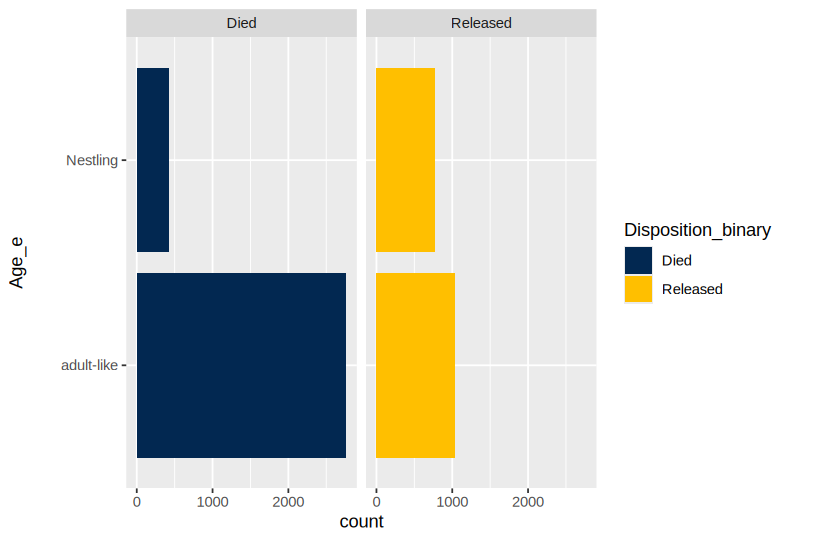

In [20]:
ggplot(df, aes(x = Age_e, y = count, fill = Disposition_binary)) +
  geom_col() +
  facet_grid(. ~ Disposition_binary) +
  coord_flip() +
  scale_fill_manual(values = c(Died = "#022851", Released = "#FFBF00"))

In [21]:
df1 <- model_data %>%
  group_by(r, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop")
df1

r,Disposition_binary,count
<chr>,<chr>,<int>
caught by domestic animal,Died,476
caught by domestic animal,Released,180
found inside,Died,122
found inside,Released,45
found on the ground,Died,1402
found on the ground,Released,717
nest-related,Died,269
nest-related,Released,426
suspect torpor-like state,Died,83


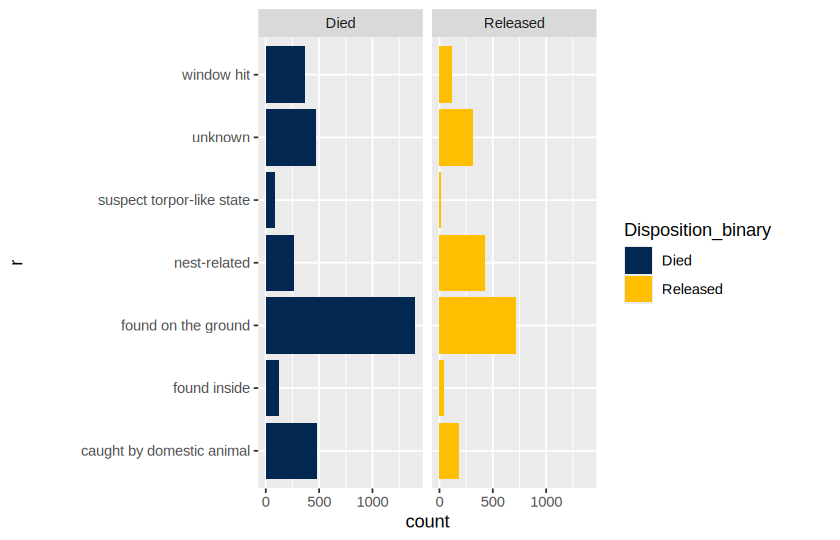

In [22]:
ggplot(df1, aes(x = r, y = count, fill = Disposition_binary)) +
  geom_col() +
  facet_grid(. ~ Disposition_binary) +
  coord_flip() +
  scale_fill_manual(values = c(Died = "#022851", Released = "#FFBF00"))

In [23]:
df2 <- model_data %>%
  group_by(season, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop")
df2

season,Disposition_binary,count
<chr>,<chr>,<int>
Fall,Died,371
Fall,Released,60
Spring,Died,1322
Spring,Released,974
Summer,Died,944
Summer,Released,588
Winter,Died,554
Winter,Released,187


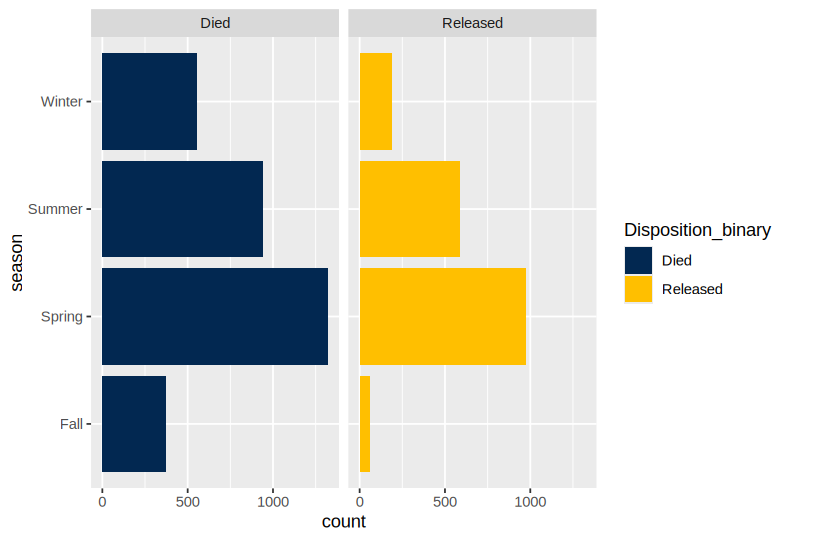

In [24]:
ggplot(df2, aes(x = season, y = count, fill = Disposition_binary)) +
  geom_col() +
  facet_grid(. ~ Disposition_binary) +
  coord_flip() +
  scale_fill_manual(values = c(Died = "#022851", Released = "#FFBF00"))

**Q11 (4 pts).** What do your tables and plots suggest? Which variables look associated with the outcome? Which **statistical test** could check whether the association is more than chance?

✍️ **Your answer:**

Adult like birds seam less likely to be realesed and birds tend to die when they are found on the ground. Although there are more deaths in Spring there are also more realsed birds suggesting they are just more animals in general. However animals in fall and winter appear to die more often than to be relaesed.

### 📊 From counts to proportions
**Q12 (5 pts).** Calculate the proportion of birds **released vs. died** at each center, show the table, and plot it as side-by-side bars.

Place,Disposition_binary,count,proportion
<chr>,<chr>,<int>,<dbl>
Lindsey,Died,2664,0.6430123
Lindsey,Released,1479,0.3569877
Santa Barbara,Died,38,0.5846154
Santa Barbara,Released,27,0.4153846
malibu,Died,489,0.6174242
malibu,Released,303,0.3825758


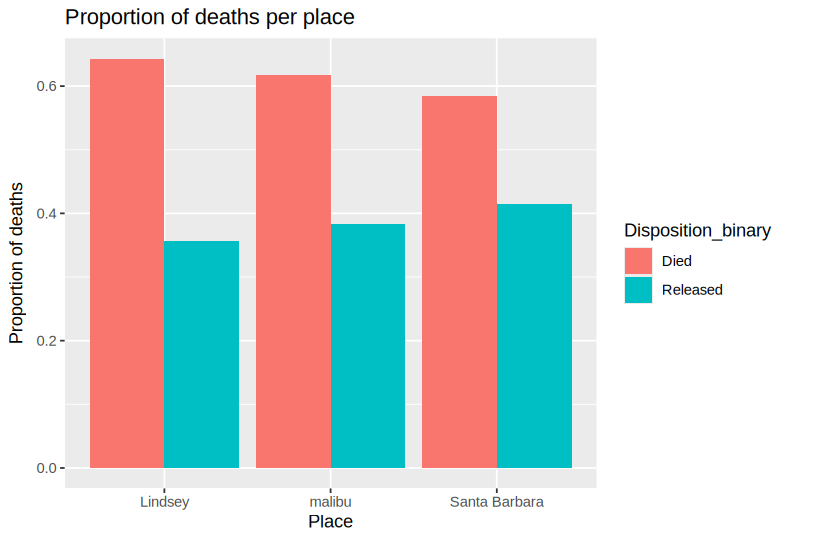

In [25]:
proportions <- model_data %>%
  group_by(Place, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop") %>%
  group_by(Place) %>%
  mutate(proportion = count / sum(count))
proportions

ggplot(proportions, aes(x = Place, y = proportion, fill = Disposition_binary)) +
  geom_col(position = "dodge") +
  xlab( "Place") +
  ylab("Proportion of deaths") +
  labs(title = "Proportion of deaths per place")

## 🧬 Case file 4 · Green birds vs. orange birds

**Q13 (5 pts).** Make a new column `Species_group` with two groups:
* **`Selasphorus`**: all *Selasphorus* birds
* **`Non-selasphorus`**: Anna's (ANHU), Black-chinned (BCHU) and unidentified non-*Selasphorus* birds

Then tabulate and plot survival by `Species_group`. **Do survival proportions differ between the groups?**

✅ *Check yourself:* the dataset already has a `Green_Orange` column. If your grouping is right, `table(model_data$Species_group, model_data$Green_Orange)` has zeros off the diagonal.

<details><summary>💡 <b>Hint</b> (try first!)</summary>

There is only **one** value that belongs in the `Selasphorus` group, so a single `ifelse()` does it: *if* `Species_e` is `"Selasphorus"`, then `"Selasphorus"`, *else* `"Non-selasphorus"`.

</details>

                 
                  Non-selasphorus spp. Selasphorus spp.
  Non-selasphorus                 4141                0
  Selasphorus                        0              859

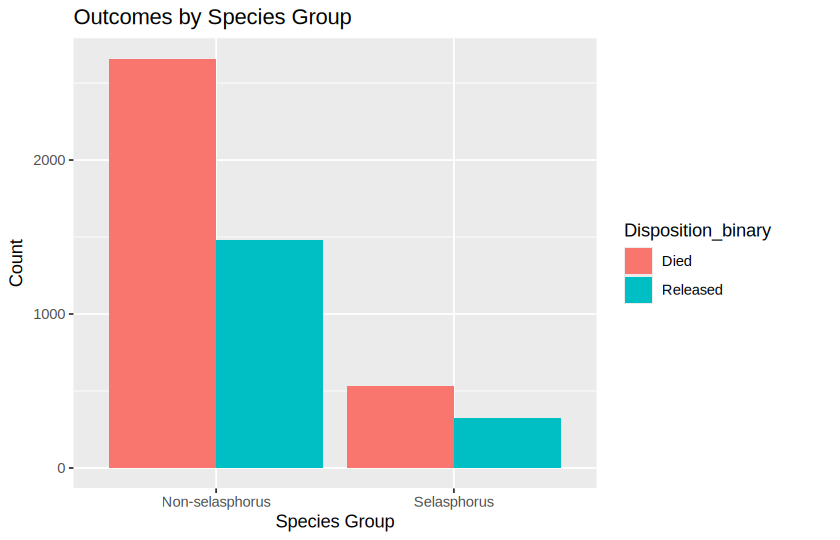

In [26]:
model_data$Species_group <- ifelse(model_data$Species_e == "Selasphorus", "Selasphorus", "Non-selasphorus")

table(model_data$Species_group, model_data$Green_Orange)   # self-check

species_distribution <- model_data %>%
  group_by(Species_group, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop")

ggplot(species_distribution, aes(x = Species_group, y = count, fill = Disposition_binary)) +
  geom_col(position = "dodge") +
  xlab("Species Group") +
  ylab("Count") +
  labs(title = "Outcomes by Species Group")

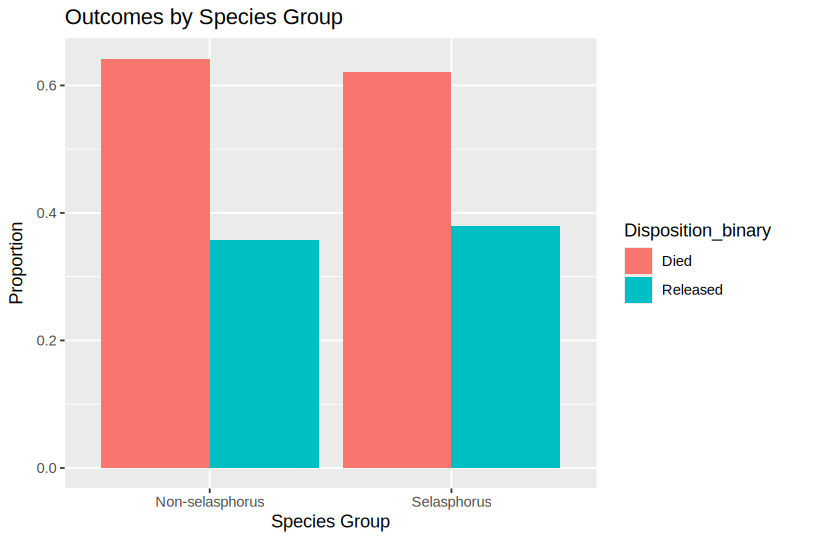

In [27]:
species_distribution_proportion <- model_data %>%
  group_by(Species_group, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop") %>%
  group_by(Species_group) %>%
  mutate(proportion = count/sum(count))

ggplot(species_distribution_proportion, aes(x = Species_group, y = proportion, fill = Disposition_binary)) +
  geom_col(position = "dodge") +
  xlab("Species Group") +
  ylab("Proportion") +
  labs(title = "Outcomes by Species Group")

✍️ **Your answer:**

The proportions of the two groups appear to be similar

## ⏳ Case file 5 · Time traveller: admissions over the years

**Q14 (2 pts).** Convert `Admitted` to a real date. Then explain what the `format` argument does, and what would happen if you used `"%d/%m/%Y"` instead.

In [28]:
model_data$Admitted_date <- as.Date(model_data$Admitted, format = "%m/%d/%Y")
class(model_data$Admitted_date)
range(model_data$Admitted_date)

[1] "Date"

[1] "1991-01-02" "2016-12-21"

✍️ **Your answer:**

The format argument on as.Date tells r what is the format the date was subbmitted as.

**Q15 (4 pts).** 🔮 *Predict first:* which **season** do you think brings the most hummingbirds into care? `Spring` Why? Because of newborns and migratory birds.

Now count admissions per **month** and per **year**, and plot both timelines. Was your season prediction right? (`table(model_data$season)` will tell you.)

In [29]:
admissions_by_month <- model_data %>%
  mutate(Admitted_month = format(Admitted_date, "%m")) %>%
  group_by(Admitted_month) %>%
  summarise(count= n_distinct(ID), .groups = "drop")

admissions_by_year <- model_data %>%
  mutate(Admitted_year = format(Admitted_date, "%Y")) %>%
  group_by(Admitted_year) %>%
  summarise( count = n_distinct(ID), .groups = "drop")

In [30]:
head(admissions_by_month)
head(admissions_by_year)

Admitted_month,count
<chr>,<int>
01,231
02,364
03,745
04,861
05,690
06,841


Admitted_year,count
<chr>,<int>
1991,139
1992,132
1993,139
1994,127
1995,136
1996,165


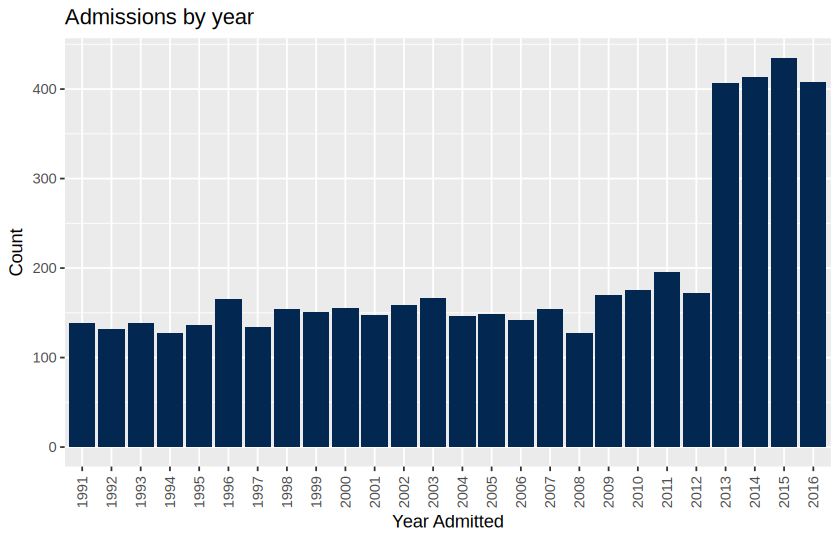

In [31]:
ggplot(admissions_by_year, aes(x = Admitted_year, y = count)) +
  geom_col(fill = "#022851") +
  xlab( "Year Admitted") +
  ylab( "Count") +
  labs(title = "Admissions by year") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))

## now plot admissions_by_month the same way

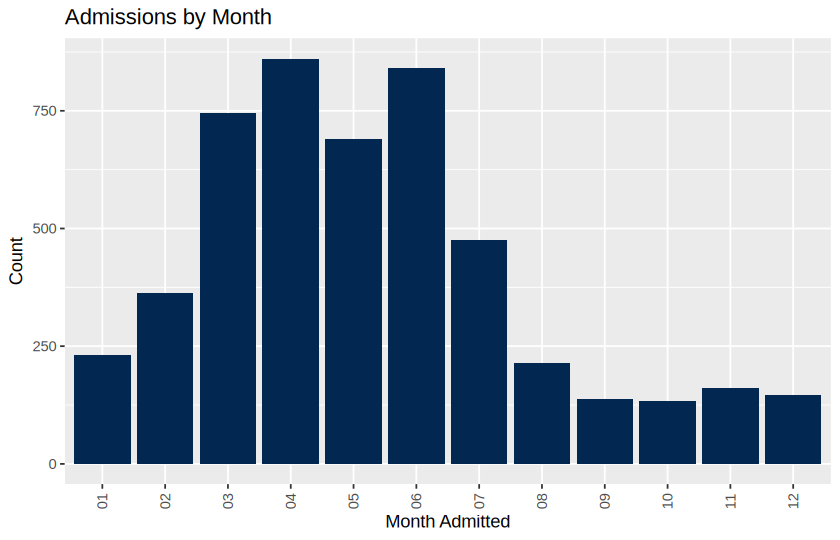

In [32]:
ggplot(admissions_by_month, aes(x = Admitted_month, y = count)) +
  geom_col(fill = "#022851") +
  xlab( "Month Admitted") +
  ylab( "Count") +
  labs(title = "Admissions by Month") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))

## now plot admissions_by_month the same way

**Q16 (2 pts).** 🕵️ **Plot twist.** Admissions roughly **triple** from 2013 onwards. Did hummingbirds suddenly get into three times more trouble? Find out what really changed.

<details><summary>💡 <b>Hint</b> (try first!)</summary>

Count admissions by year **and** `Place`: `model_data %>% count(Admitted_year = format(Admitted_date, "%Y"), Place)`. When does each center first appear?

</details>

In [33]:
# your investigation here


In [34]:
addmitted_year_place <-model_data %>%
  count (Admitted_year = format(Admitted_date, "%Y"), Place )
addmitted_year_place

Admitted_year,Place,n
<chr>,<chr>,<int>
1991,Lindsey,139
1992,Lindsey,132
1993,Lindsey,139
1994,Lindsey,127
1995,Lindsey,136
1996,Lindsey,165
1997,Lindsey,134
1998,Lindsey,154
1999,Lindsey,151


✍️ **Your answer:**

The Rehabilitation center of Malibu opened in 2012 and the rehabilitation center of Santa Barbar opened in 2016


## 🕵️ Bonus · Data detective (+5 pts)

Real data are messy, and these data have **at least three problems** hiding in the *raw* file (`data`). Find three, show the code that reveals each one, and say how you would fix it **without overwriting the raw file**.

<details><summary>💡 <b>Hint</b> (try first!)</summary>

Try `summary(data$Brought_in_after)`, `unique(data$Sex_e)` (look *very* closely at the spaces), and `unique(data$Place)` (look at capitalisation).

</details>

In [35]:
# your detective work here
summary(data$Brought_in_after)
unique(data$Sex_e)
unique(data$Place)

     Min.   1st Qu.    Median      Mean   3rd Qu.      Max. 
 -365.000     0.000     0.000     3.058     1.000 16588.000 

[1] "Female-like " "unknown"      "Male"

[1] "Lindsey"       "malibu"        "Santa Barbara"

✍️ **Your answer:**

-There are numbers that must be errors on the column brought_in after_becasue the minumum is a negative number and the maximum is 16588.
-There is a space after Female-Like
-For places Malibu does not have a capital letter

## 💭 Debrief (2 pts)

**Q17.** In two or three sentences: (a) one thing in this data that surprised you, and (b) one R error you hit and how you fixed it.

✍️ **Your answer:**

It would have taken a longtime for me to  realize why there were more deaths after 2013. My first thought wasn't that they opened more centers. b) I had to change the code of addmitted by month to only "m%", because it had originally "m%-y%" and the plot was almost impossible to read.

## 🎨 Hall of Fame (optional, not graded)
Make your **most beautiful** plot from this dataset, in Aggie Blue `#022851` and Aggie Gold `#FFBF00`. The best ones get shown in class. 🏆

## 📤 How to submit
1. Run every cell from the top (**Runtime → Restart and run all**) so the outputs are fresh.
2. Save the notebook to **your branch** of the course GitHub repo: File → Save a copy in GitHub (**never `main`**).
3. Download and submit `Hummingbird_data_YOURNAME.csv` and `rehab_counts_YOURNAME.pdf` from `outputs/`.

In [36]:
beep_colab("smb_stage_clear")   # mission complete 🍄

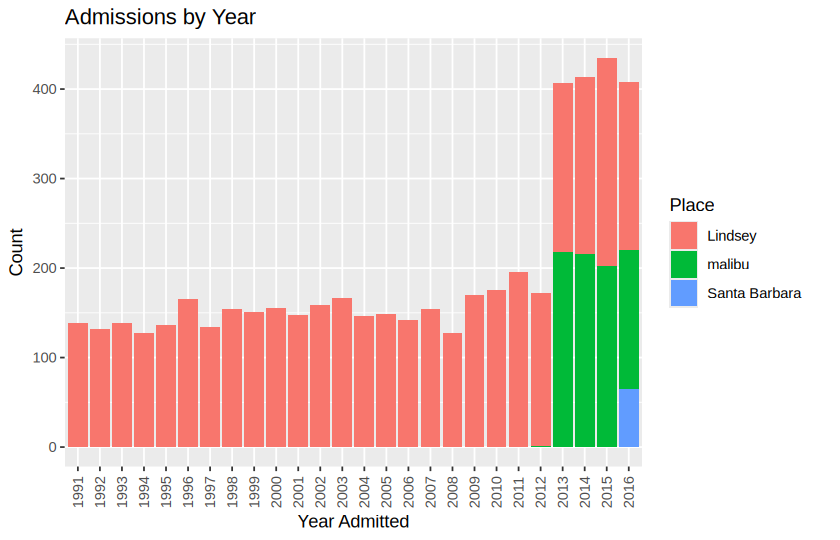

In [37]:
ggplot(addmitted_year_place, aes(x = Admitted_year, y = n, fill = Place)) +
  geom_col() +
  xlab("Year Admitted") +
  ylab("Count") +
  labs(title = "Admissions by Year") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))

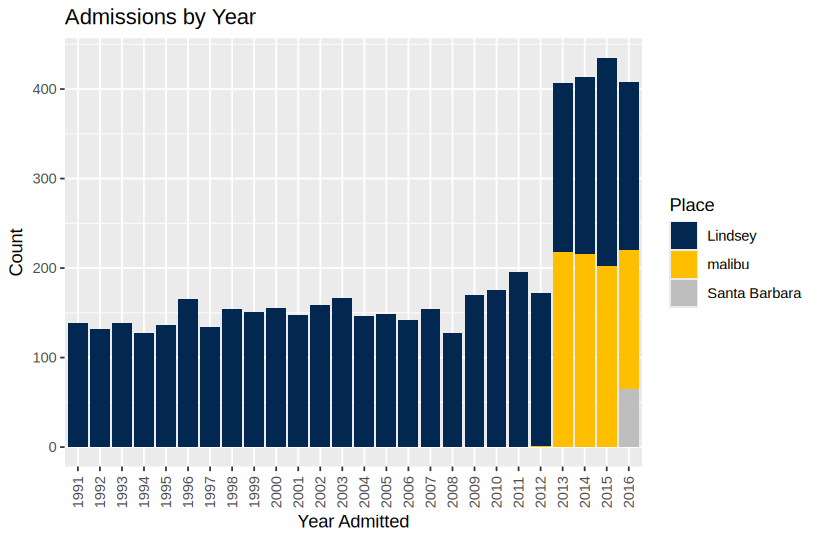

In [38]:
library(ggplot2)

ggplot(addmitted_year_place, aes(x = Admitted_year, y = n, fill = Place)) +
  geom_col() +
  scale_fill_manual(values = c(
    "Lindsey" = "#022851",        # Aggie Blue
    "malibu" = "#FFBF00",         # Aggie Gold
    "Santa Barbara" = "gray"
  )) +
  xlab("Year Admitted") +
  ylab("Count") +
  labs(title = "Admissions by Year") +
  theme(axis.text.x =element_text(angle =90, vjust =0.5))

**New Plot**
Create a timeline plot of monthly hummingbird admissions.

Differentiate between species groups using the Species group column.

Your plot should show admissions for two distinct species groups over time.

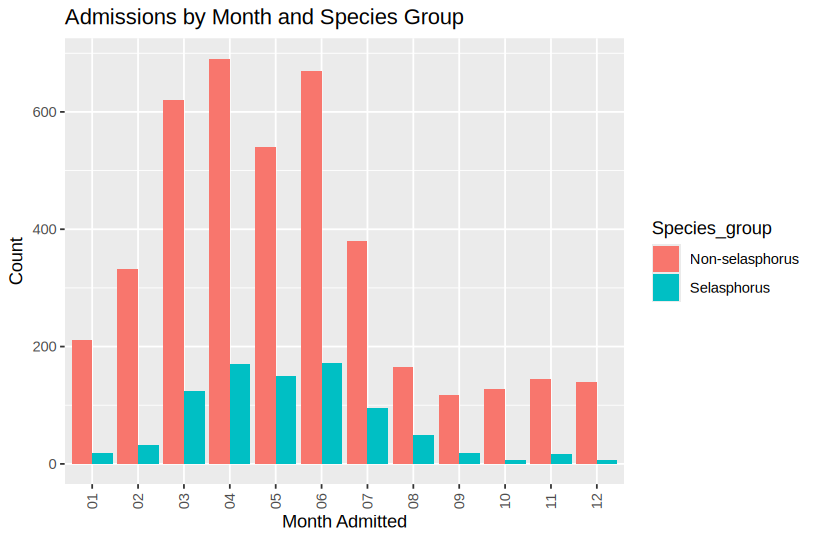

In [39]:
admissions_by_month_species <- model_data %>%
  mutate(Admitted_month = format(Admitted_date, "%m")) %>%
  group_by(Admitted_month, Species_group) %>%
  summarise(count = n_distinct(ID), .groups = "drop")

ggplot(admissions_by_month_species, aes(x = Admitted_month, y = count, fill = Species_group)) +
  geom_col(position = "dodge") +
  xlab("Month Admitted") +
  ylab("Count") +
  labs(title = "Admissions by Month and Species Group") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))

# Section 4: Running full model and model selection

1. Complete the code and fit a full model

In [44]:
fullmodel = glm(as.factor(Disposition_binary) ~ r + Green_Orange + season + F_Aid + Species_e, data = model_data, family = binomial(link = "logit"))
fullmodel


Call:  glm(formula = as.factor(Disposition_binary) ~ r + Green_Orange + 
    season + F_Aid + Species_e, family = binomial(link = "logit"), 
    data = model_data)

Coefficients:
                 (Intercept)                 rfound inside  
                    -1.94321                       0.12184  
        rfound on the ground                 rnest-related  
                     0.13535                       0.65855  
  rsuspect torpor-like state                      runknown  
                    -0.96929                       0.40668  
                 rwindow hit  Green_OrangeSelasphorus spp.  
                    -0.04662                       0.25421  
                seasonSpring                  seasonSummer  
                     1.07507                       0.93947  
                seasonWinter                      F_AidYes  
                     0.49263                      -0.05978  
               Species_eBCHU      Species_eNon-selasphorus  
                     0.4134

2. use following command with full model to do stepwise model selection

In [45]:
backward_model = step(fullmodel,k=2,direction = "backward",test="Chisq")

Start:  AIC=5972.7
as.factor(Disposition_binary) ~ r + Green_Orange + season + F_Aid + 
    Species_e


Step:  AIC=5972.7
as.factor(Disposition_binary) ~ r + season + F_Aid + Species_e

            Df Deviance    AIC     LRT  Pr(>Chi)    
- F_Aid      1   5945.5 5971.5   0.805    0.3697    
<none>           5944.7 5972.7                      
- r          6   6001.5 6017.5  56.788 2.017e-10 ***
- season     3   6028.6 6050.6  83.852 < 2.2e-16 ***
- Species_e  3   6133.3 6155.3 188.567 < 2.2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Step:  AIC=5971.51
as.factor(Disposition_binary) ~ r + season + Species_e

            Df Deviance    AIC     LRT  Pr(>Chi)    
<none>           5945.5 5971.5                      
- r          6   6002.6 6016.6  57.113 1.733e-10 ***
- season     3   6029.1 6049.1  83.620 < 2.2e-16 ***
- Species_e  3   6133.8 6153.8 188.300 < 2.2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


In [46]:
forward_model = step(fullmodel ,k=2,direction = ,test="Chisq")

Start:  AIC=5972.7
as.factor(Disposition_binary) ~ r + Green_Orange + season + F_Aid + 
    Species_e


Step:  AIC=5972.7
as.factor(Disposition_binary) ~ r + season + F_Aid + Species_e

            Df Deviance    AIC     LRT  Pr(>Chi)    
- F_Aid      1   5945.5 5971.5   0.805    0.3697    
<none>           5944.7 5972.7                      
- r          6   6001.5 6017.5  56.788 2.017e-10 ***
- season     3   6028.6 6050.6  83.852 < 2.2e-16 ***
- Species_e  3   6133.3 6155.3 188.567 < 2.2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Step:  AIC=5971.51
as.factor(Disposition_binary) ~ r + season + Species_e

            Df Deviance    AIC     LRT  Pr(>Chi)    
<none>           5945.5 5971.5                      
- r          6   6002.6 6016.6  57.113 1.733e-10 ***
- season     3   6029.1 6049.1  83.620 < 2.2e-16 ***
- Species_e  3   6133.8 6153.8 188.300 < 2.2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


### !!!Answer Questions in the Assignment

# Section 5: explore the glm object

In [53]:
names(backward_model)

[1] "coefficients"      "residuals"         "fitted.values"    
 [4] "effects"           "R"                 "rank"             
 [7] "qr"                "family"            "linear.predictors"
[10] "deviance"          "aic"               "null.deviance"    
[13] "iter"              "weights"           "prior.weights"    
[16] "df.residual"       "df.null"           "y"                
[19] "converged"         "boundary"          "model"            
[22] "call"              "formula"           "terms"            
[25] "data"              "offset"            "control"          
[28] "method"            "contrasts"         "xlevels"          
[31] "anova"

Q1:How many model properties are available?
Our model has 31 properties

In [54]:
length(names(backward_model))

[1] 31

explore individual attributes of the fitted model and read about it in the R documentation

In [50]:
install.packages("sjPlot")
library(sjPlot)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘rbibutils’, ‘Rdpack’, ‘reformulas’, ‘effectsize’, ‘bayestestR’, ‘datawizard’, ‘ggeffects’, ‘insight’, ‘parameters’, ‘performance’, ‘sjlabelled’, ‘sjmisc’, ‘sjstats’



Attaching package: ‘sjPlot’


The following object is masked from ‘package:ggplot2’:

    set_theme




In [56]:
tab_model(backward_model)


In [58]:
# 1. Create the model table using tab_model
table_html <- tab_model(backward_model)

# 2. Use IRdisplay to render the HTML directly in the Colab output
IRdisplay::display_html(as.character(table_html))

as.factor(Disposition_binary) 
 
 
 Predictors 
 Odds Ratios 
 CI 
 p 
 
 
 (Intercept) 
 0.14 
 0.10 – 0.19 
 <0.001 
 
 
 r [found inside] 
 1.13 
 0.76 – 1.66 
 0.538 
 
 
 r [found on the ground] 
 1.14 
 0.93 – 1.39 
 0.206 
 
 
 r [nest-related] 
 1.93 
 1.49 – 2.49 
 <0.001 
 
 
 r [suspect torpor-like state] 
 0.38 
 0.18 – 0.72 
 0.005 
 
 
 r [unknown] 
 1.51 
 1.19 – 1.91 
 0.001 
 
 
 r [window hit] 
 0.96 
 0.72 – 1.27 
 0.764 
 
 
 season [Spring] 
 2.93 
 2.20 – 3.95 
 <0.001 
 
 
 season [Summer] 
 2.56 
 1.91 – 3.47 
 <0.001 
 
 
 season [Winter] 
 1.64 
 1.19 – 2.28 
 0.003 
 
 
 Species e [BCHU] 
 1.51 
 0.74 – 3.02 
 0.243 
 
 
 Species e [Non-selasphorus] 
 3.31 
 2.79 – 3.94 
 <0.001 
 
 
 Species e [Selasphorus] 
 1.29 
 1.09 – 1.52 
 0.004 
 
 
 Observations 
 5000 
 
 
 R 2 Tjur 
 0.118 
 

 
 
 
 

 
 
 
 
   
 as.factor(Disposition_binary) 
 
 
 Predictors 
 Odds Ratios 
 CI 
 p 
 
 
 (Intercept) 
 0.14 
 0.10 – 0.19 
 <0.001 
 
 
 r [found inside] 
 1.13 
 0.76 – 1.66 
 0.538 
 
 
 r [found on the ground] 
 1.14 
 0.93 – 1.39 
 0.206 
 
 
 r [nest-related] 
 1.93 
 1.49 – 2.49 
 <0.001 
 
 
 r [suspect torpor-like state] 
 0.38 
 0.18 – 0.72 
 0.005 
 
 
 r [unknown] 
 1.51 
 1.19 – 1.91 
 0.001 
 
 
 r [window hit] 
 0.96 
 0.72 – 1.27 
 0.764 
 
 
 season [Spring] 
 2.93 
 2.20 – 3.95 
 <0.001 
 
 
 season [Summer] 
 2.56 
 1.91 – 3.47 
 <0.001 
 
 
 season [Winter] 
 1.64 
 1.19 – 2.28 
 0.003 
 
 
 Species e [BCHU] 
 1.51 
 0.74 – 3.02 
 0.243 
 
 
 Species e [Non-selasphorus] 
 3.31 
 2.79 – 3.94 
 <0.001 
 
 
 Species e [Selasphorus] 
 1.29 
 1.09 – 1.52 
 0.004 
 
 
 Observations 
 5000 
 
 
 R 2 Tjur 
 0.118 
 

 

 
 
   
 as.factor(Disposition_binary) 
 
 
 Predictors 
 Odds Ratios 
 CI 
 p 
 
 
 (Intercept) 
 0.14 
 0.10 – 0.19 
 <0.001 
 
 
 r [found inside] 
 1.13 
 0.76 – 1.66 
 0.538 
 
 
 r [found on the ground] 
 1.14 
 0.93 – 1.39 
 0.206 
 
 
 r [nest-related] 
 1.93 
 1.49 – 2.49 
 <0.001 
 
 
 r [suspect torpor-like state] 
 0.38 
 0.18 – 0.72 
 0.005 
 
 
 r [unknown] 
 1.51 
 1.19 – 1.91 
 0.001 
 
 
 r [window hit] 
 0.96 
 0.72 – 1.27 
 0.764 
 
 
 season [Spring] 
 2.93 
 2.20 – 3.95 
 <0.001 
 
 
 season [Summer] 
 2.56 
 1.91 – 3.47 
 <0.001 
 
 
 season [Winter] 
 1.64 
 1.19 – 2.28 
 0.003 
 
 
 Species e [BCHU] 
 1.51 
 0.74 – 3.02 
 0.243 
 
 
 Species e [Non-selasphorus] 
 3.31 
 2.79 – 3.94 
 <0.001 
 
 
 Species e [Selasphorus] 
 1.29 
 1.09 – 1.52 
 0.004 
 
 
 Observations 
 5000 
 
 
 R 2 Tjur 
 0.118 
 

 
NULLTRUE

In [57]:
summary(backward_model)


Call:
glm(formula = as.factor(Disposition_binary) ~ r + season + Species_e, 
    family = binomial(link = "logit"), data = model_data)

Coefficients:
                           Estimate Std. Error z value Pr(>|z|)    
(Intercept)                -1.96125    0.16025 -12.239  < 2e-16 ***
rfound inside               0.12285    0.19933   0.616 0.537677    
rfound on the ground        0.12971    0.10258   1.264 0.206077    
rnest-related               0.65515    0.12990   5.043 4.58e-07 ***
rsuspect torpor-like state -0.97316    0.34886  -2.790 0.005279 ** 
runknown                    0.41157    0.11957   3.442 0.000578 ***
rwindow hit                -0.04264    0.14234  -0.300 0.764495    
seasonSpring                1.07480    0.14888   7.219 5.23e-13 ***
seasonSummer                0.93808    0.15231   6.159 7.32e-10 ***
seasonWinter                0.49429    0.16629   2.973 0.002954 ** 
Species_eBCHU               0.41513    0.35593   1.166 0.243478    
Species_eNon-selasphorus    1.197

Q2: Which variable has the highest odds ratio for survival?
The highest odds ratio for survival is "Species Non-Selasphorus"

Q3: Do the calculated odds ratios match the values provided by sjPlot?
Yes